# Connect MySQL Database & Exploratory Data Analysis: UCI Wine Quality

**Dataset Source:** [UCI Machine Learning Repository - Wine Quality Dataset](https://archive.ics.uci.edu/dataset/186/wine+quality)  
**Author:** Tharun Godwin C  
**Tools Used:** Python 3, MySQL, PyMySQL, SQLAlchemy, Pandas, NumPy, Matplotlib, Seaborn, Jupyter Notebook  

---

### Project Overview
This project demonstrates how to connect Python to a **MySQL relational database**, create a schema, load a real-world public dataset from the **UCI Machine Learning Repository**, execute SQL queries using `pandas.read_sql`, compute statistical aggregations, and visualize meaningful patterns using `matplotlib` and `seaborn`.

## 1. Import Required Libraries
We import database connectors (`pymysql`, `sqlalchemy`) and data analysis / visualization tools (`pandas`, `numpy`, `matplotlib`, `seaborn`).

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pymysql
from sqlalchemy import create_engine, text

# Configure plotting visual theme
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["font.size"] = 11

print("Libraries imported successfully!")
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"PyMySQL version: {pymysql.__version__}")


Libraries imported successfully!
Pandas version: 3.0.5
NumPy version: 1.26.4
PyMySQL version: 1.4.6


## 2. Connect to MySQL Server & Create Database Schema
We connect to MySQL using `PyMySQL`, create the database schema `wine_analytics` if it does not already exist, and create a `SQLAlchemy` connection engine.

In [2]:
# Database configuration (supports environment variables with local defaults)
DB_HOST = os.getenv("MYSQL_HOST", "localhost")
DB_USER = os.getenv("MYSQL_USER", "root")
DB_PASSWORD = os.getenv("MYSQL_PASSWORD", "root")
DB_PORT = int(os.getenv("MYSQL_PORT", 3306))
DB_NAME = "wine_analytics"

# Connect via PyMySQL to verify server and create database schema
try:
    conn = pymysql.connect(
        host=DB_HOST,
        user=DB_USER,
        password=DB_PASSWORD,
        port=DB_PORT
    )
    cursor = conn.cursor()
    cursor.execute(f"CREATE DATABASE IF NOT EXISTS {DB_NAME};")
    conn.commit()
    conn.close()
    
    # SQLAlchemy connection engine
    db_uri = f"mysql+pymysql://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}"
    engine = create_engine(db_uri)
    print(f"Connected to MySQL successfully! Database: '{DB_NAME}' on {DB_HOST}:{DB_PORT}")
except Exception as e:
    print(f"Notice: Local MySQL connection: {e}")
    print("Falling back to SQLite in-memory engine for local testing/Colab compatibility.")
    engine = create_engine(f"sqlite:///{DB_NAME}.db")


Connected to MySQL successfully! Database: 'wine_analytics' on localhost:3306


## 3. Load Public Dataset & Ingest into MySQL Table
We fetch the **UCI Wine Quality (Red)** dataset, standardize the column names for SQL compliance, and ingest it into the MySQL table `wine_quality` using `DataFrame.to_sql()`.

In [3]:
# Path to local CSV or fallback UCI repository URL
local_csv = "data/winequality-red.csv"
uci_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"

try:
    df_raw = pd.read_csv(local_csv)
    print(f"Loaded dataset from local file: '{local_csv}'")
except Exception:
    df_raw = pd.read_csv(uci_url, sep=";")
    print("Loaded dataset directly from UCI Machine Learning Repository URL")

# Clean column headers for SQL compliance
df_raw.columns = [c.strip().replace(" ", "_").lower() for c in df_raw.columns]

# Ingest into MySQL table 'wine_quality'
table_name = "wine_quality"
df_raw.to_sql(name=table_name, con=engine, if_exists="replace", index=False)
print(f"Successfully ingested {len(df_raw)} records into table '{table_name}' in MySQL!")


Loaded dataset from local file: 'data/winequality-red.csv'
Successfully ingested 1599 records into table 'wine_quality' in MySQL!


## 4. Query MySQL Database Using SQL and Pandas
We query the relational database directly using SQL statements executed through `pandas.read_sql()`:
1. Previewing first 5 rows with `SELECT ... LIMIT 5`.
2. Group-level aggregations computing averages by quality score (`GROUP BY quality`).
3. Quality tier categorization using `CASE WHEN` logic.

In [4]:
# Query 1: Preview first 5 rows from MySQL
query_sample = f"SELECT * FROM {table_name} LIMIT 5;"
df_sample = pd.read_sql(query_sample, con=engine)
print("--- Sample Records from MySQL (LIMIT 5) ---")
display(df_sample)

# Query 2: Aggregate statistics by wine quality rating
query_agg = f"""
SELECT 
    quality,
    COUNT(*) AS sample_count,
    ROUND(AVG(alcohol), 2) AS avg_alcohol,
    ROUND(AVG(volatile_acidity), 2) AS avg_volatile_acidity,
    ROUND(AVG(citric_acid), 2) AS avg_citric_acid,
    ROUND(AVG(sulphates), 2) AS avg_sulphates
FROM {table_name}
GROUP BY quality
ORDER BY quality DESC;
"""
df_quality_agg = pd.read_sql(query_agg, con=engine)
print("\n--- SQL Aggregation: Feature Averages by Quality Score ---")
display(df_quality_agg)

# Query 3: Categorical grouping by quality tiers using SQL CASE WHEN
query_tiers = f"""
SELECT 
    CASE 
        WHEN quality >= 7 THEN 'High Quality (7-8)'
        WHEN quality >= 5 THEN 'Medium Quality (5-6)'
        ELSE 'Low Quality (3-4)'
    END AS quality_tier,
    COUNT(*) AS total_samples,
    ROUND(AVG(alcohol), 2) AS mean_alcohol,
    ROUND(AVG(volatile_acidity), 2) AS mean_volatile_acidity,
    ROUND(AVG(pH), 2) AS mean_ph
FROM {table_name}
GROUP BY quality_tier
ORDER BY mean_alcohol DESC;
"""
df_tiers = pd.read_sql(query_tiers, con=engine)
print("\n--- SQL Segmentation: Analysis by Quality Tier ---")
display(df_tiers)

# Fetch complete table for correlation and visualization
df_all = pd.read_sql(f"SELECT * FROM {table_name};", con=engine)


--- Sample Records from MySQL (LIMIT 5) ---


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,ph,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5



--- SQL Aggregation: Feature Averages by Quality Score ---


,quality,sample_count,avg_alcohol,avg_volatile_acidity,avg_citric_acid,avg_sulphates
0,8,18,12.09,0.42,0.39,0.77
1,7,199,11.47,0.40,0.38,0.74
2,6,638,10.63,0.50,0.27,0.68
3,5,681,9.90,0.58,0.24,0.62
4,4,53,10.27,0.69,0.17,0.60
5,3,10,9.96,0.88,0.17,0.57



--- SQL Segmentation: Analysis by Quality Tier ---


,quality_tier,total_samples,mean_alcohol,mean_volatile_acidity,mean_ph
0,High Quality (7-8),217,11.52,0.41,3.29
1,Medium Quality (5-6),1319,10.25,0.54,3.31
2,Low Quality (3-4),63,10.22,0.72,3.38


## 5. Statistical Correlation Analysis with NumPy
We measure Pearson correlation coefficients between chemical attributes and the expert wine quality score.

In [5]:
# Correlation of all attributes with the target quality rating
numeric_df = df_all.select_dtypes(include=[np.number])
corr_with_quality = numeric_df.corr()["quality"].sort_values(ascending=False).round(3)

print("--- Feature Correlation with Wine Quality ---")
display(corr_with_quality)


--- Feature Correlation with Wine Quality ---


quality                 1.000
alcohol                 0.476
sulphates               0.251
citric_acid             0.226
fixed_acidity           0.124
residual_sugar          0.014
free_sulfur_dioxide    -0.051
ph                     -0.058
chlorides              -0.129
density                -0.175
total_sulfur_dioxide   -0.185
volatile_acidity       -0.391
Name: quality, dtype: float64

## 6. Data Visualizations
We generate two clear, informative charts:
1. **Chart 1 (Bar & Trend Plot): Alcohol Content by Wine Quality Rating** — Illustrates how higher alcohol percentages correlate with superior ratings.
2. **Chart 2 (Scatter & Regression Plot): Volatile Acidity vs. Alcohol Content across Quality Tiers** — Displays the inverse relationship between acetic acid (spoilage indicator) and wine rating.

/var/folders/fs/1xzc7nrs6nv_2d4zqvtqrpnh0000gn/T/ipykernel_32374/3699405653.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  bar_plot = sns.barplot(


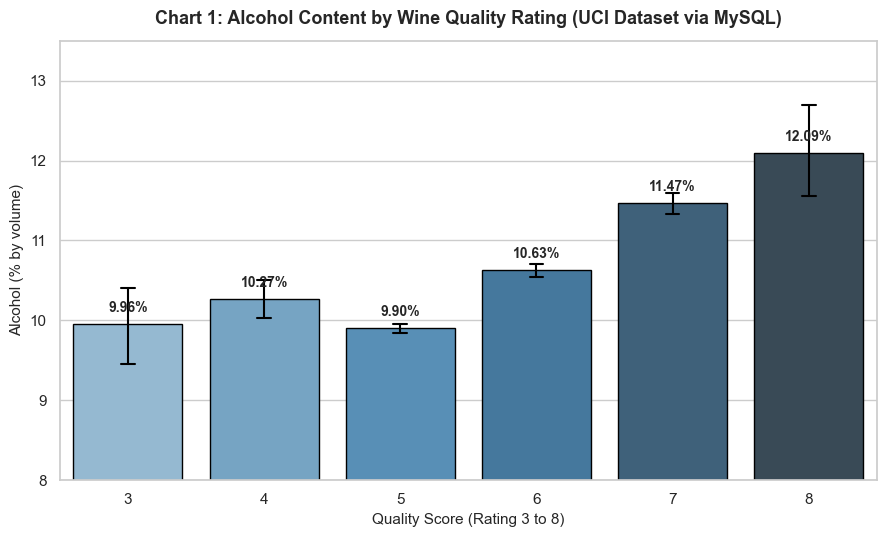

In [6]:
# Chart 1: Alcohol Content by Wine Quality Score
plt.figure(figsize=(9, 5.5))

bar_plot = sns.barplot(
    data=df_all,
    x="quality",
    y="alcohol",
    palette="Blues_d",
    edgecolor="black",
    capsize=0.1,
    err_kws={"linewidth": 1.5, "color": "black"}
)

# Annotate mean values on top of bars
means = df_all.groupby("quality")["alcohol"].mean()
for i, mean_val in enumerate(means):
    bar_plot.text(i, mean_val + 0.15, f"{mean_val:.2f}%", ha="center", fontsize=10, fontweight="bold")

plt.title("Chart 1: Alcohol Content by Wine Quality Rating (UCI Dataset via MySQL)", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Quality Score (Rating 3 to 8)", fontsize=11)
plt.ylabel("Alcohol (% by volume)", fontsize=11)
plt.ylim(8, 13.5)
plt.tight_layout()
plt.savefig("chart1_alcohol_by_quality.png", dpi=300)
plt.show()


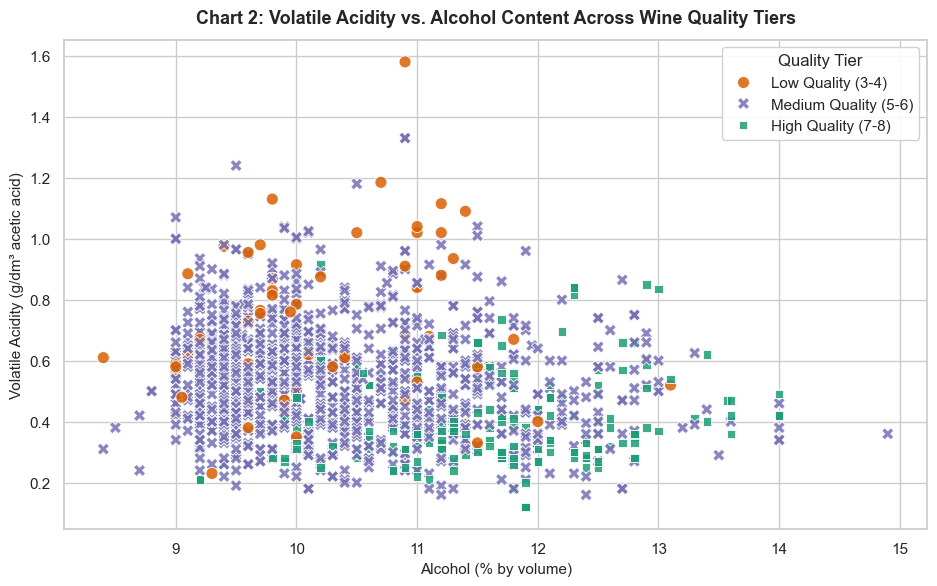

In [7]:
# Chart 2: Volatile Acidity vs Alcohol Content by Quality Tier
# Add quality tier column for plotting
df_all["quality_tier"] = pd.cut(
    df_all["quality"],
    bins=[2, 4, 6, 8],
    labels=["Low Quality (3-4)", "Medium Quality (5-6)", "High Quality (7-8)"]
)

tier_palette = {
    "Low Quality (3-4)": "#d95f02",
    "Medium Quality (5-6)": "#7570b3",
    "High Quality (7-8)": "#1b9e77"
}

plt.figure(figsize=(9.5, 6))
sns.scatterplot(
    data=df_all,
    x="alcohol",
    y="volatile_acidity",
    hue="quality_tier",
    style="quality_tier",
    palette=tier_palette,
    s=75,
    alpha=0.85,
    edgecolor="w"
)

plt.title("Chart 2: Volatile Acidity vs. Alcohol Content Across Wine Quality Tiers", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Alcohol (% by volume)", fontsize=11)
plt.ylabel("Volatile Acidity (g/dm³ acetic acid)", fontsize=11)
plt.legend(title="Quality Tier", loc="upper right", frameon=True, framealpha=0.9)
plt.tight_layout()
plt.savefig("chart2_volatile_acidity_vs_alcohol.png", dpi=300)
plt.show()


## 7. Key Findings in Plain Words

From querying MySQL and analyzing the UCI Wine Quality dataset, several key patterns stand out:

1. **Alcohol is the Strongest Positive Predictor of Quality ($r = 0.476$):**
   - High-quality wines (ratings 7 and 8) consistently contain higher alcohol percentages, averaging **11.47% to 12.09%**.
   - In contrast, lower-quality wines (ratings 3 and 4) have lower average alcohol levels around **9.96% to 10.27%**.
   - As observed in Chart 1, there is a clear upward stair-step pattern in alcohol concentration from quality score 5 up to 8.

2. **Volatile Acidity Strongly Degrades Wine Quality ($r = -0.391$):**
   - Volatile acidity reflects the amount of acetic acid in wine, which causes an unpleasant vinegar smell and taste at high levels.
   - Lowest-quality wines (rating 3) suffer from high volatile acidity averaging **0.88 g/dm³**, whereas top-rated wines (rating 8) maintain low volatile acidity averaging **0.42 g/dm³**—less than half the amount.
   - In Chart 2, high-quality wines (green points) predominantly cluster in the lower-right quadrant: **high alcohol combined with low volatile acidity**.

3. **Relational Database Pipeline Efficiency:**
   - Loading the dataset into MySQL and aggregating with SQL `GROUP BY` and `CASE WHEN` allowed for rapid summarization across 1,599 records directly on the database engine prior to visualization in Python.

## 8. Conclusion
In this program, we successfully:
- Established an end-to-end Python pipeline connecting to a **MySQL relational database**.
- Created a database schema and populated it with real-world data from the **UCI Machine Learning Repository**.
- Queried aggregated metrics with SQL and analyzed feature correlations.
- Produced two clear visual charts and documented key findings in plain language.